# This Project for me Learning How to code Polynomial Regression in Machine Learning 

## Import Library What We Need

In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 

## Load Dataset

In [34]:
df = pd.read_csv('../dataset/train_housePrices.csv')

## Data Understanding

In [35]:
df.shape

(1460, 81)

In [36]:
df.head(10)

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000
5,6,50,RL,85.0,14115,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,MnPrv,Shed,700,10,2009,WD,Normal,143000
6,7,20,RL,75.0,10084,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,8,2007,WD,Normal,307000
7,8,60,RL,NaN,10382,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,Shed,350,11,2009,WD,Normal,200000
8,9,50,RM,51.0,6120,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2008,WD,Abnorml,129900
9,10,190,RL,50.0,7420,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,1,2008,WD,Normal,118000


In [37]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

In [38]:
df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


## Exploratory Data Analysis (EDA)

In [39]:
# Check Missing Value
print(df.isnull().sum().sort_values(ascending=False))

PoolQC           1453
MiscFeature      1406
Alley            1369
Fence            1179
MasVnrType        872
                 ... 
MoSold              0
YrSold              0
SaleType            0
SaleCondition       0
SalePrice           0
Length: 81, dtype: int64


In [40]:
# Check duplicate data
print(df.duplicated().sum())

0


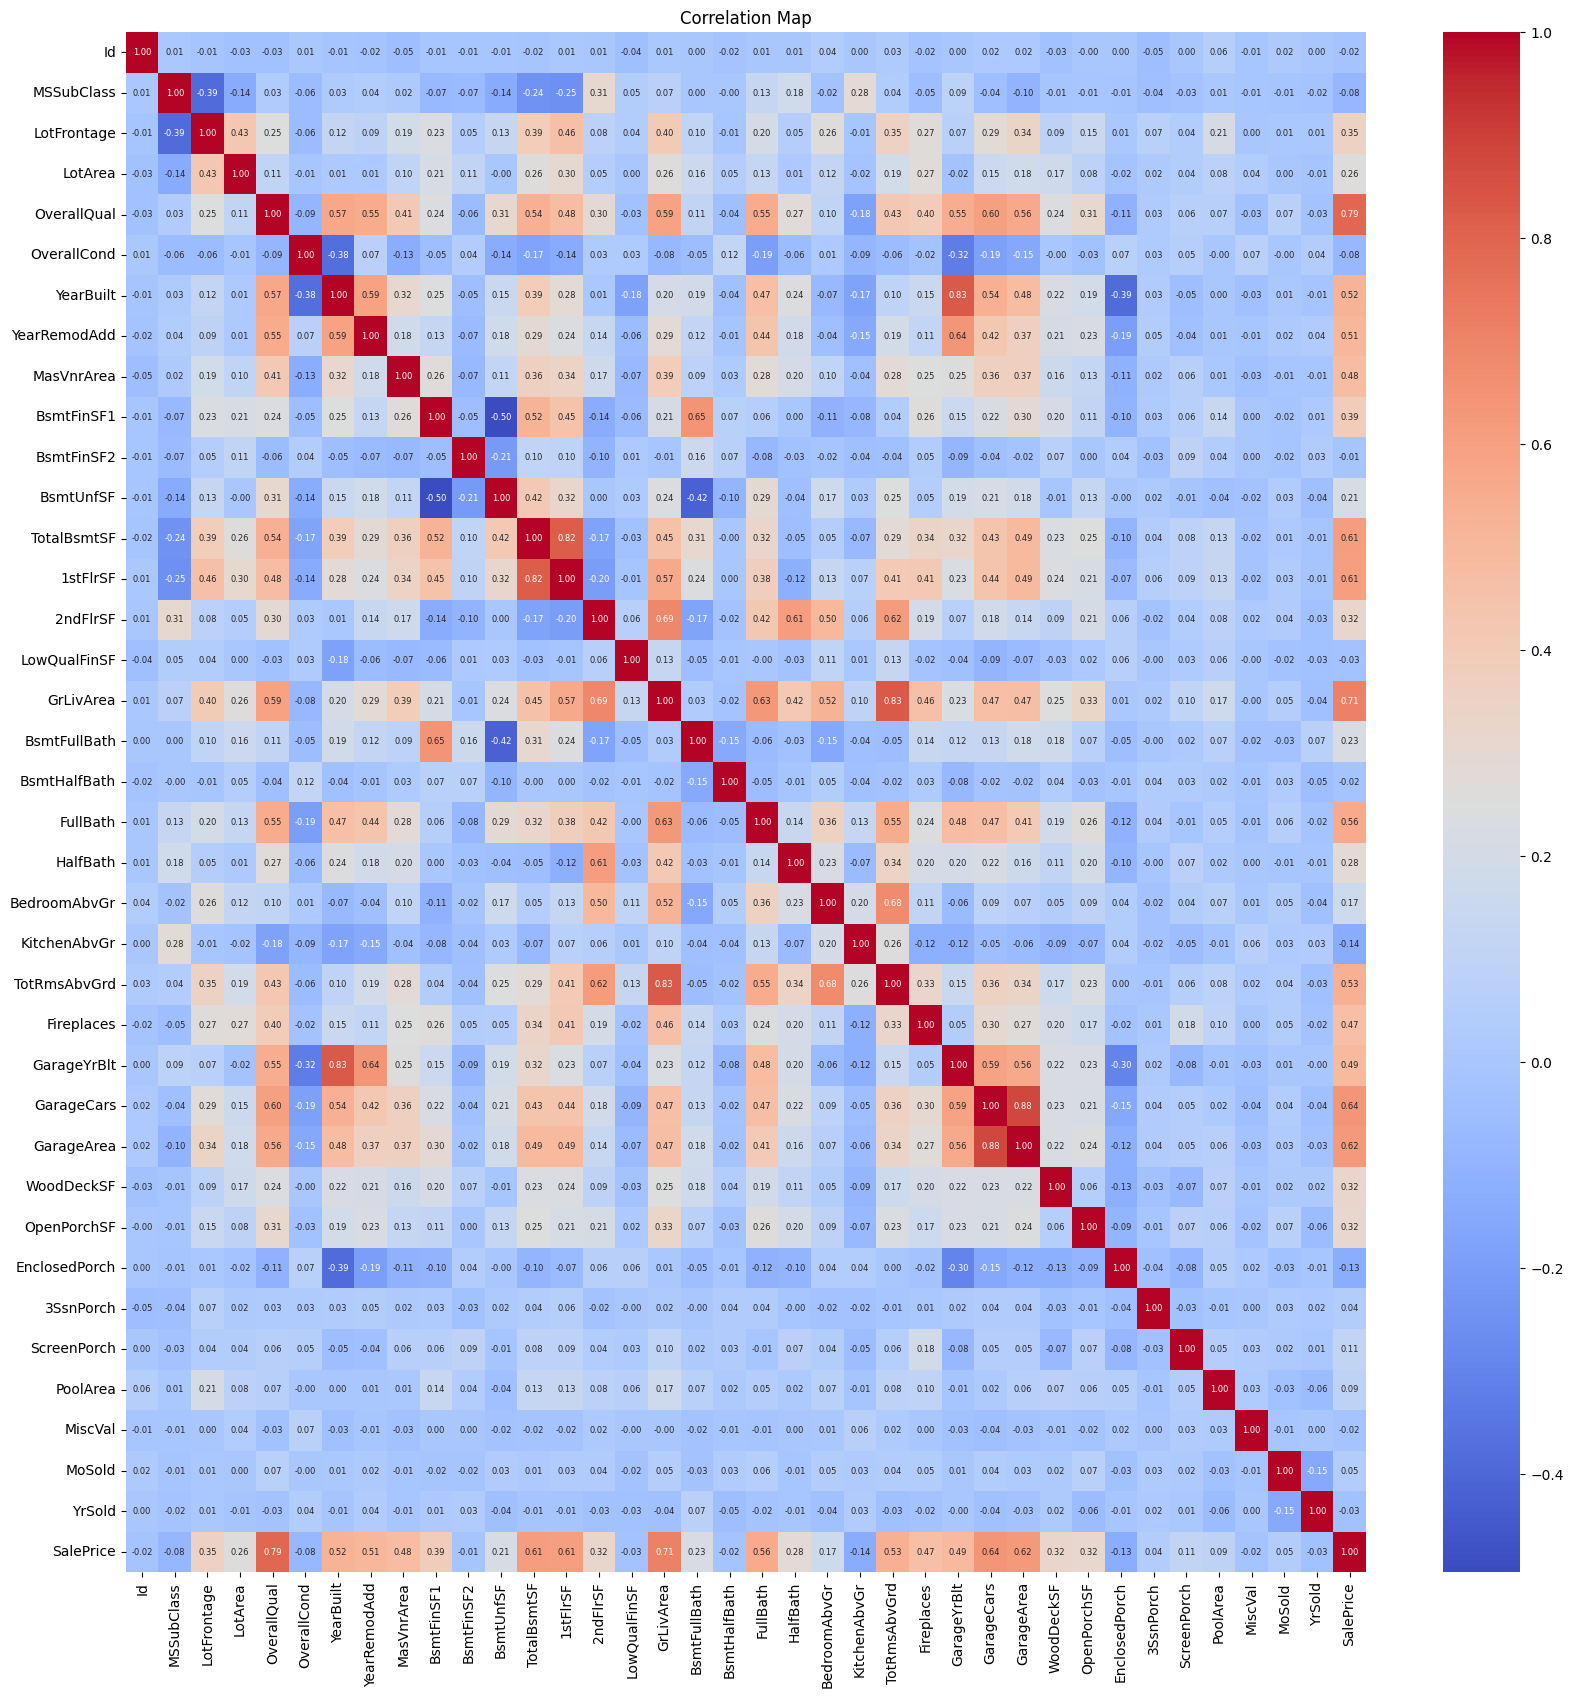

In [41]:
# Visulatization Correlation
corr = df.corr(numeric_only=True)
plt.figure(figsize=(20,20))
sns.heatmap(
    corr, 
    annot=True, 
    cmap="coolwarm",
    fmt=".2f",
    annot_kws={"size":6}
)
plt.title("Correlation Map")
plt.show()

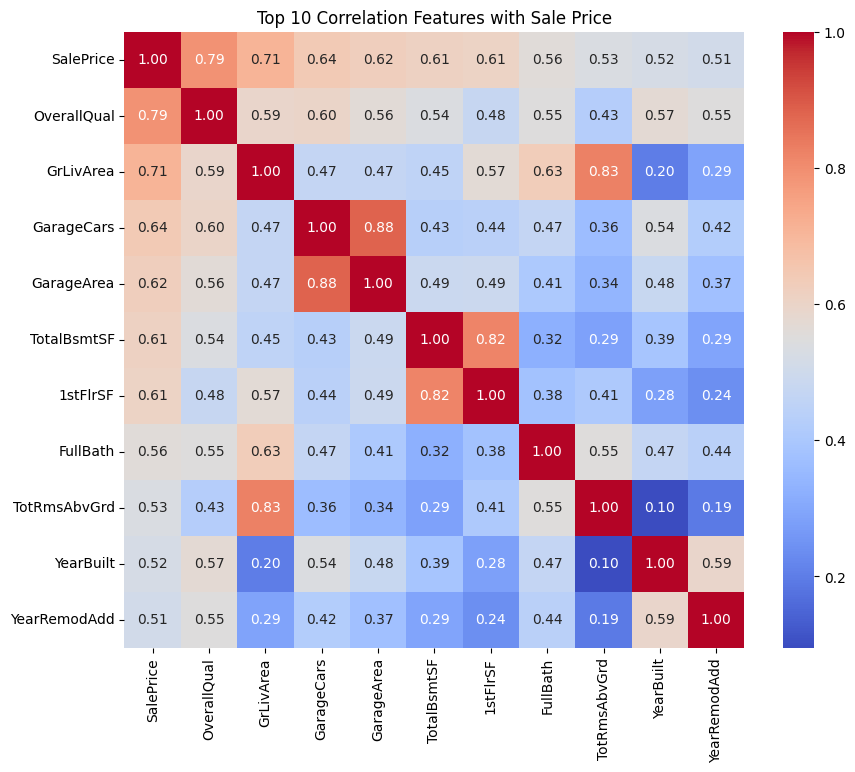

In [42]:
# Correlation map for top 10 Features
corr = df.corr(numeric_only=True)

top_corr = (
    corr['SalePrice']
    .abs()
    .sort_values(ascending=False)
    .head(11)
)

top_features = top_corr.index

plt.figure(figsize=(10,8))
sns.heatmap(
    corr.loc[top_features, top_features],
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)
plt.title("Top 10 Correlation Features with Sale Price")
plt.show()

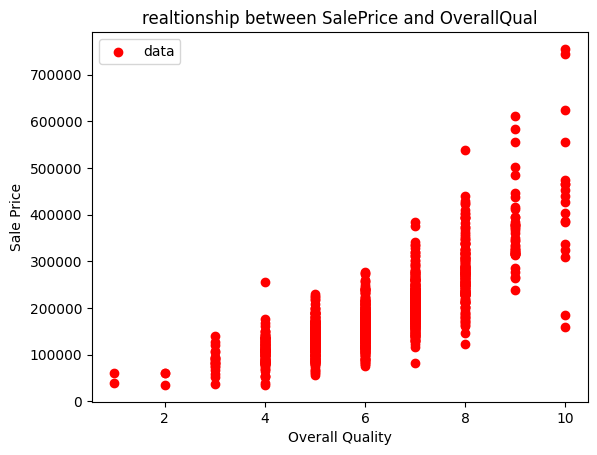

In [43]:
# Make Scatter Visualization
plt.scatter(x=df['OverallQual'], y=df['SalePrice'], color='red', label='data')
plt.xlabel('Overall Quality')
plt.ylabel("Sale Price")
plt.legend()
plt.title("realtionship between SalePrice and OverallQual")
plt.show()

# Conlucions
# We can see at visulization, relation between SP and AQ enough strong but we still can see outlier on 10 OQ and 700000 SP 

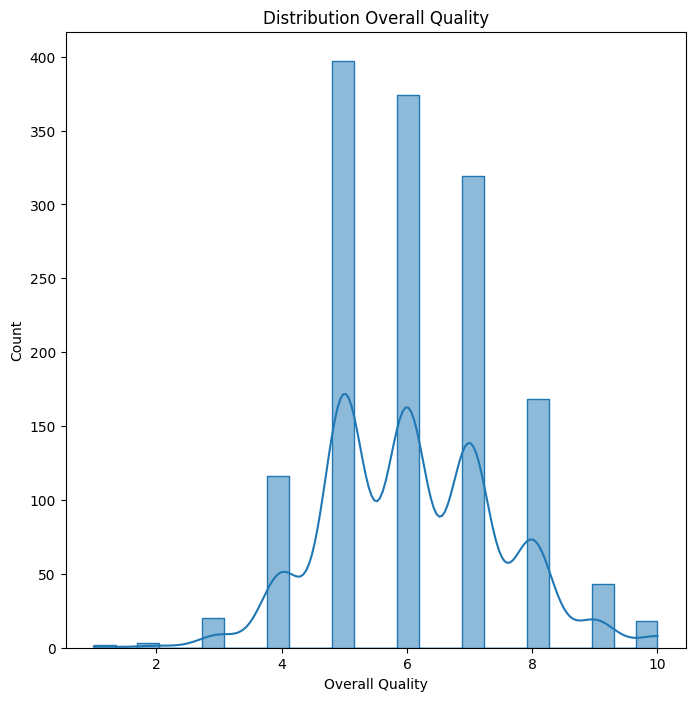

In [44]:
# Check Distribution X 
plt.figure(figsize=(8,8))
sns.histplot(data= df, x=df['OverallQual'], kde=True, element='step')
plt.xlabel("Overall Quality")
plt.ylabel("Count")
plt.title("Distribution Overall Quality")
plt.show()


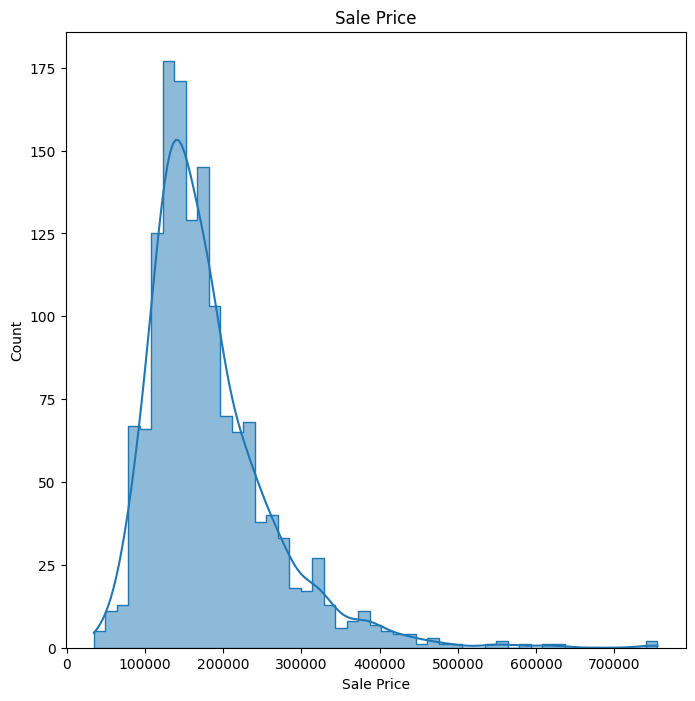

In [45]:
# Check Distribution y 
plt.figure(figsize=(8,8))
sns.histplot(data= df, x=df['SalePrice'], kde=True, element='step')
plt.xlabel("Sale Price")
plt.ylabel("Count")
plt.title("Sale Price")
plt.show()

C:\Users\ROG\AppData\Local\Temp\ipykernel_18204\3297588854.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


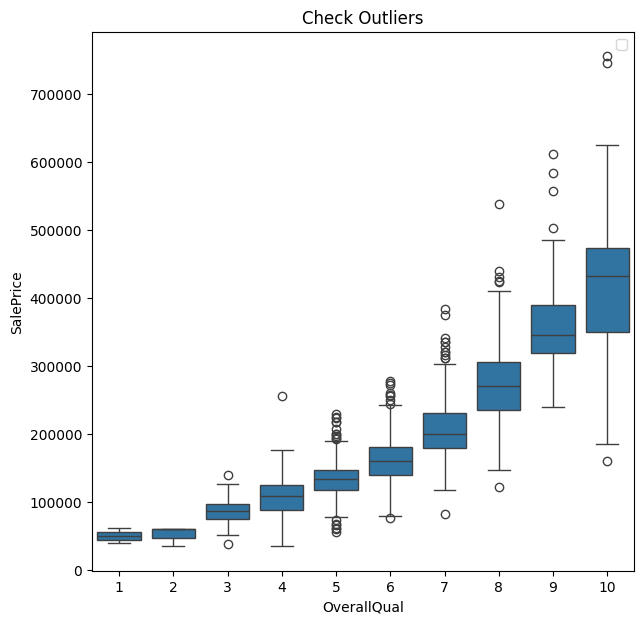

In [46]:
# We gonna check outliers between SP and OQ
plt.figure(figsize=(7,7))
sns.boxplot(data= df, x=df['OverallQual'],y=df['SalePrice'])
plt.title("Check Outliers")
plt.legend()
plt.show()

## Data Cleaning
### We gonna drop coloumn
- PoolQC           1453
- MiscFeature      1406
- Alley            1369
- Fence            1179
Because the missing value > 50%, so i decide to drop them, and we can see at corr map they're not in 10 features strongest

In [47]:
# Drop Coloumn
df = df.drop('PoolQC', axis=1)
df = df.drop('MiscFeature', axis=1)
df = df.drop('Alley', axis=1)
df = df.drop('Fence', axis=1)

print("Drop Column Success")

Drop Column Success


In [48]:
# Check missing value after drop coloumn
print(df.isnull().sum().sort_values(ascending=False).to_string())

MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageFinish      81
GarageQual        81
GarageCond        81
GarageType        81
GarageYrBlt       81
BsmtExposure      38
BsmtFinType2      38
BsmtCond          37
BsmtFinType1      37
BsmtQual          37
MasVnrArea         8
Electrical         1
LandSlope          0
LotConfig          0
Condition1         0
Neighborhood       0
LotShape           0
Street             0
LotArea            0
MSZoning           0
MSSubClass         0
Id                 0
Utilities          0
LandContour        0
RoofStyle          0
YearRemodAdd       0
Foundation         0
ExterCond          0
ExterQual          0
Exterior2nd        0
RoofMatl           0
Exterior1st        0
BsmtFinSF2         0
BsmtFinSF1         0
BsmtUnfSF          0
TotalBsmtSF        0
Condition2         0
BldgType           0
OverallCond        0
YearBuilt          0
HouseStyle         0
OverallQual        0
LowQualFinSF       0
2ndFlrSF           0
1stFlrSF     

In [49]:
# i will fill MasVnrType with None, because this coloumn might be use later
df['MasVnrType'] = df['MasVnrType'].fillna('None')
print("Fill Succes")

# Check Missing Value :
print(df.isnull().sum().sort_values(ascending=False).to_string())

Fill Succes
FireplaceQu      690
LotFrontage      259
GarageFinish      81
GarageYrBlt       81
GarageQual        81
GarageCond        81
GarageType        81
BsmtExposure      38
BsmtFinType2      38
BsmtCond          37
BsmtQual          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
Neighborhood       0
LandSlope          0
LotConfig          0
Condition1         0
LandContour        0
LotShape           0
Street             0
LotArea            0
MSZoning           0
MSSubClass         0
Id                 0
Utilities          0
RoofMatl           0
RoofStyle          0
Condition2         0
Foundation         0
ExterCond          0
ExterQual          0
MasVnrType         0
Exterior1st        0
Exterior2nd        0
BsmtFinSF2         0
BsmtFinSF1         0
BsmtUnfSF          0
TotalBsmtSF        0
HouseStyle         0
BldgType           0
OverallCond        0
YearBuilt          0
YearRemodAdd       0
OverallQual        0
LowQualFinSF       0
2ndFlrSF           0
1

## Data Handling
because we have other coloumn with missing value but < 50%, so i will fill those coloumn with any metode

In [50]:
# These coloumn will be fill with None because these coloumn is Categorical
cols_none =[
    "FireplaceQu",
    "GarageFinish",
    "GarageQual",
    "GarageCond",
    "GarageType",
    "BsmtExposure",
    "BsmtCond",
    "BsmtQual",
    "BsmtFinType1",
    "BsmtFinType2"
]
df[cols_none] = df[cols_none].fillna('None')
print("Fill Success")

print(df.isnull().sum().sort_values(ascending=False).to_string())

Fill Success
LotFrontage      259
GarageYrBlt       81
MasVnrArea         8
Electrical         1
Id                 0
Street             0
LotShape           0
LandContour        0
Utilities          0
LotConfig          0
MSSubClass         0
MSZoning           0
LotArea            0
Condition1         0
Neighborhood       0
LandSlope          0
HouseStyle         0
OverallCond        0
YearBuilt          0
YearRemodAdd       0
Condition2         0
RoofStyle          0
RoofMatl           0
Exterior2nd        0
Exterior1st        0
MasVnrType         0
ExterQual          0
ExterCond          0
BldgType           0
Foundation         0
BsmtQual           0
BsmtExposure       0
BsmtCond           0
BsmtFinSF1         0
BsmtFinType2       0
BsmtFinSF2         0
BsmtFinType1       0
BsmtUnfSF          0
TotalBsmtSF        0
HeatingQC          0
Heating            0
CentralAir         0
1stFlrSF           0
2ndFlrSF           0
OverallQual        0
LowQualFinSF       0
GrLivArea          0


In [51]:
# coloumn LotFrontage will be fill with groupby Neighborhood and median
df['LotFrontage'] = (
    df.groupby('Neighborhood')['LotFrontage']
    .transform(lambda x: x.fillna(x.median())))
print("Median Fill Success\n")
print(df.isnull().sum().sort_values(ascending=False).to_string())

Median Fill Success

GarageYrBlt      81
MasVnrArea        8
Electrical        1
MSSubClass        0
Id                0
Street            0
LotShape          0
LandContour       0
Utilities         0
LotConfig         0
MSZoning          0
LotFrontage       0
LotArea           0
Condition1        0
Neighborhood      0
LandSlope         0
HouseStyle        0
OverallCond       0
YearBuilt         0
YearRemodAdd      0
Condition2        0
RoofStyle         0
RoofMatl          0
Exterior2nd       0
Exterior1st       0
MasVnrType        0
ExterQual         0
ExterCond         0
BldgType          0
Foundation        0
BsmtQual          0
BsmtExposure      0
BsmtCond          0
BsmtFinSF1        0
BsmtFinType2      0
BsmtFinSF2        0
BsmtFinType1      0
BsmtUnfSF         0
TotalBsmtSF       0
HeatingQC         0
Heating           0
CentralAir        0
1stFlrSF          0
2ndFlrSF          0
OverallQual       0
LowQualFinSF      0
GrLivArea         0
BsmtHalfBath      0
BsmtFullBath      0

In [52]:
# Coloumn GarageYrBlt will be fill with 0 because i assume if NaN in this coloumn its mean 0 garage
df['GarageYrBlt'] = df['GarageYrBlt'].fillna(0)
print("Fill Success")

Fill Success


In [53]:
# Coloumn MasVnrArea will be fill with 0
df['MasVnrArea'] = df['MasVnrArea'].fillna(0)
print("Fill Success")

Fill Success


In [54]:
# Coloumn Electrical Mode
df['Electrical'] = df['Electrical'].fillna(df['Electrical'].mode()[0])
print("Fill Success")

Fill Success


In [55]:
# Check Missing Value after we handling those data
print(df.isnull().sum().sort_values(ascending=False).to_string())

Id               0
MSSubClass       0
MSZoning         0
LotFrontage      0
LotArea          0
Street           0
LotShape         0
LandContour      0
Utilities        0
LotConfig        0
LandSlope        0
Neighborhood     0
Condition1       0
Condition2       0
BldgType         0
HouseStyle       0
OverallQual      0
OverallCond      0
YearBuilt        0
YearRemodAdd     0
RoofStyle        0
RoofMatl         0
Exterior1st      0
Exterior2nd      0
MasVnrType       0
MasVnrArea       0
ExterQual        0
ExterCond        0
Foundation       0
BsmtQual         0
BsmtCond         0
BsmtExposure     0
BsmtFinType1     0
BsmtFinSF1       0
BsmtFinType2     0
BsmtFinSF2       0
BsmtUnfSF        0
TotalBsmtSF      0
Heating          0
HeatingQC        0
CentralAir       0
Electrical       0
1stFlrSF         0
2ndFlrSF         0
LowQualFinSF     0
GrLivArea        0
BsmtFullBath     0
BsmtHalfBath     0
FullBath         0
HalfBath         0
BedroomAbvGr     0
KitchenAbvGr     0
KitchenQual 

## Splitting Data first model

In [56]:
# Import Library
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures

selected_feature = [
    'OverallQual',
    'GrLivArea',
    'GarageCars',
    'GarageArea',
    'TotalBsmtSF',
    '1stFlrSF',
    'FullBath',
    'YearBuilt'
]

# Feature Selection
X = df[selected_feature]
y = df['SalePrice']

# Spliitting data
X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y, 
    test_size=0.2, 
    random_state=42
)

## Train model and Evaluation

In [63]:
from sklearn.linear_model import Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
# Transform Features to polynomial features
degrees = [1, 2, 3, 4, 5]

# Save Model and Prediction Result
models = {}
ridge_residual_dict = {}
lasso_residual_dict = {}

# for dataframe
result = []



# Looping for all degrees
for degree in degrees :
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_sclaed = scaler.transform(X_test)

    poly_feature = PolynomialFeatures(degree=degree, include_bias=False)
    X_train_poly = poly_feature.fit_transform(X_train_scaled)
    X_test_poly = poly_feature.transform(X_test_sclaed)
 
   # Ridge
    ridge_model = Ridge(alpha=1)
    ridge_model.fit(X_train_poly, y_train)
    rigde_pred = ridge_model.predict(X_test_poly)

    # Lasso
    lasso_model = Lasso(alpha=1)
    lasso_model.fit(X_train_poly, y_train)
    lassso_pred = lasso_model.predict(X_test_poly)

    # Ridge Residual
    ridge_residual = y_test - rigde_pred

    # Saving Ridge Residual
    ridge_residual_dict[degree] = ridge_residual

    # Mean Ridge Residual
    mean_ridge_residual = ridge_residual.mean()

    # Lasso Residual
    lasso_residual = y_test - lassso_pred

    # Saving Lasso Residual
    lasso_residual_dict[degree] = lasso_residual

    # Mean Lasso Residual
    mean_lasso_residual = lasso_residual.mean()


    # Evaluation Ridge per degrees
    r_mae = mean_absolute_error(y_test, rigde_pred)
    r_rmse = np.sqrt(mean_squared_error(y_test, rigde_pred))
    r_r2 = r2_score(y_test, rigde_pred)

    # Evaluation Ridge per degrees
    l_mae = mean_absolute_error(y_test, lassso_pred)
    l_rmse = np.sqrt(mean_squared_error(y_test, lassso_pred))
    l_r2 = r2_score(y_test, lassso_pred)



    # Print Evaluation
    result.append({
        'Degree Ridge' : degree,
        'Mean Ridge Residual' : mean_ridge_residual,
        'rMAE' : r_mae,
        'rRMSE' : r_rmse,
        'rR2' : r_r2,
        'Deggre Lasso' :degree,
        'Mean Lasso Residual' : mean_lasso_residual,
        'lMAE' : l_mae,
        'lRMSE' : l_rmse,
        'lR2' : l_r2

    })


    # Saving Model and Polynomial Transform
    models[degree] ={
        'poly' : poly_feature,
        'ridge model' : ridge_model,
        'lasso model' : lasso_model,
        'ridge prediction' : rigde_pred,
        'lasso prediction' : lassso_pred
    }
result_df = pd.DataFrame(result)
print(result_df)


c:\Users\ROG\anaconda3\envs\deep_learning\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.740e+11, tolerance: 6.967e+08
  model = cd_fast.enet_coordinate_descent(
c:\Users\ROG\anaconda3\envs\deep_learning\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.546e+11, tolerance: 6.967e+08
  model = cd_fast.enet_coordinate_descent(
c:\Users\ROG\anaconda3\envs\deep_learning\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasi

   Degree Ridge  Mean Ridge Residual          rMAE          rRMSE        rR2  \
0             1          3648.207739  24928.277876   39562.120852   0.795946   
1             2          1155.474468  21746.446833   33484.420635   0.853825   
2             3         -1481.063098  24398.945960   51743.644401   0.650940   
3             4          1178.002615  49535.231050  230688.807762  -5.938079   
4             5        -17953.917436  99448.892928  534166.822469 -36.199747   

   Deggre Lasso  Mean Lasso Residual          lMAE          lRMSE       lR2  
0             1          3648.241803  24932.644215   39559.161690  0.795976  
1             2          1148.446637  21782.346277   33530.720273  0.853421  
2             3         -1310.073231  24446.732187   43737.995462  0.750596  
3             4          3643.652883  26424.342031   49261.456650  0.683626  
4             5          7849.282745  36150.166103  102074.270395 -0.358372  


c:\Users\ROG\anaconda3\envs\deep_learning\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.292e+11, tolerance: 6.967e+08
  model = cd_fast.enet_coordinate_descent(


# Visualization Ridge Residual

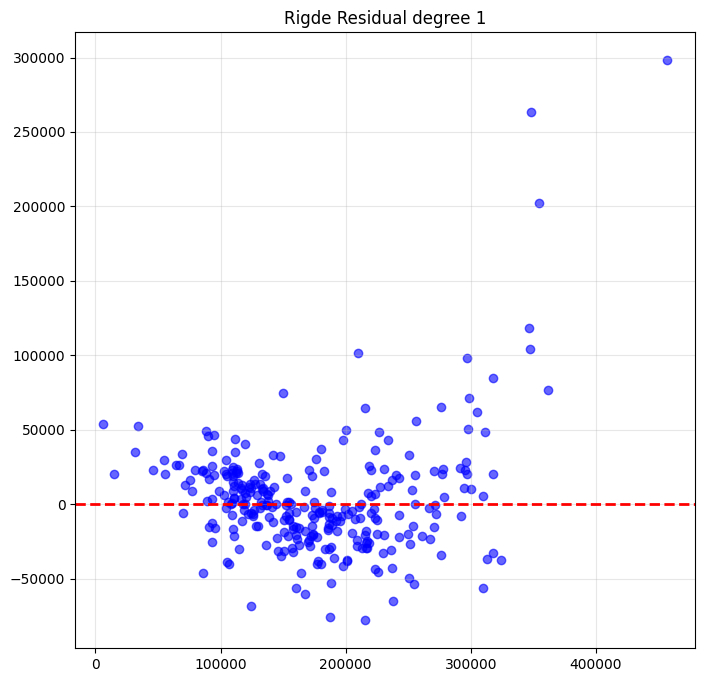

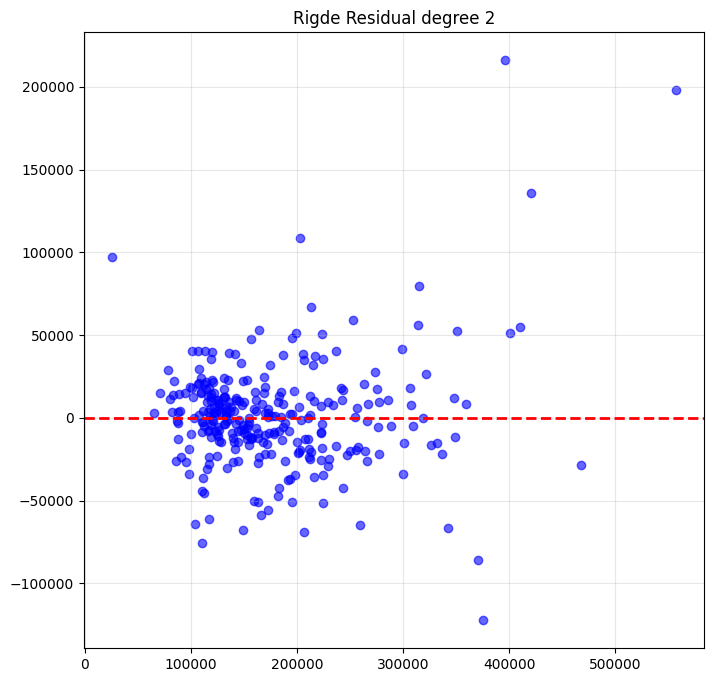

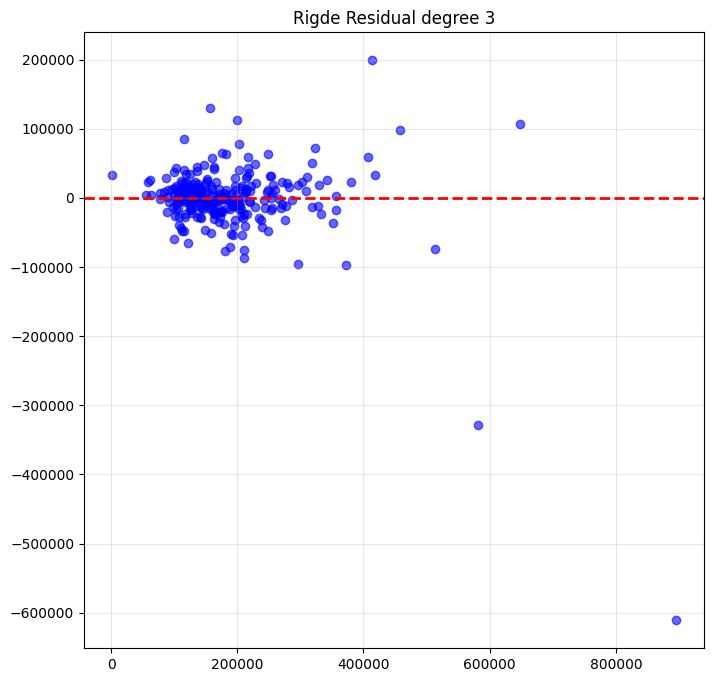

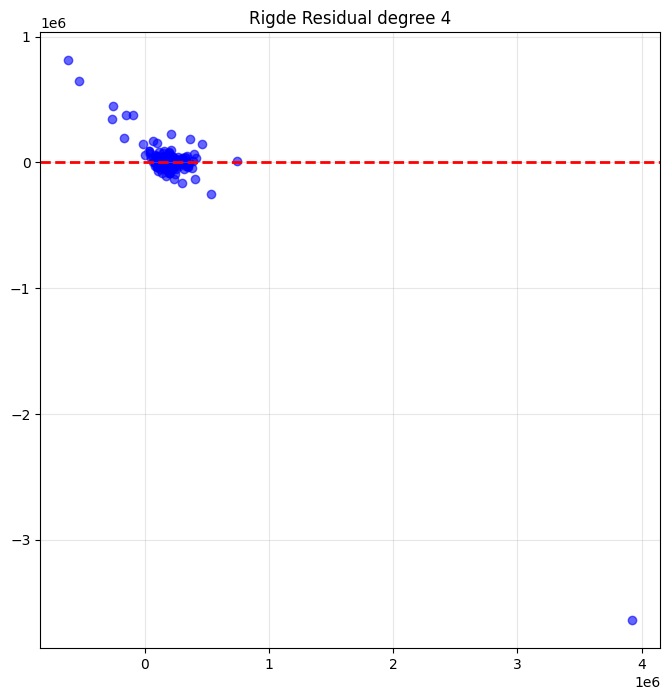

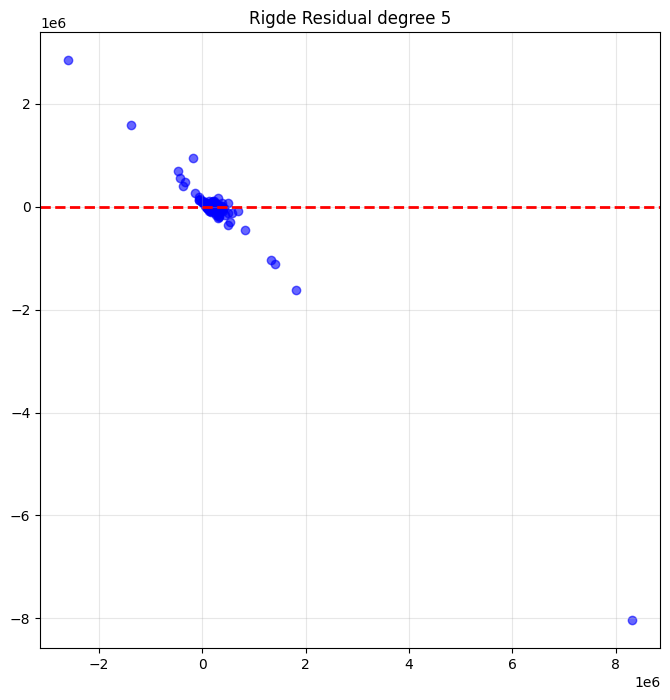

In [64]:
for degree in degrees :
    rigde_pred = models[degree]['ridge prediction']
    residual = ridge_residual_dict[degree]

    plt.figure(figsize=(8,8))
    plt.scatter(rigde_pred, residual, color='blue', alpha=0.6)
    plt.axhline(0, color='red', linestyle='--', linewidth=2)
    plt.title(f"Rigde Residual degree {degree}")
    plt.grid(alpha=0.3)
    plt.show()

# Visualization Lasso Residual

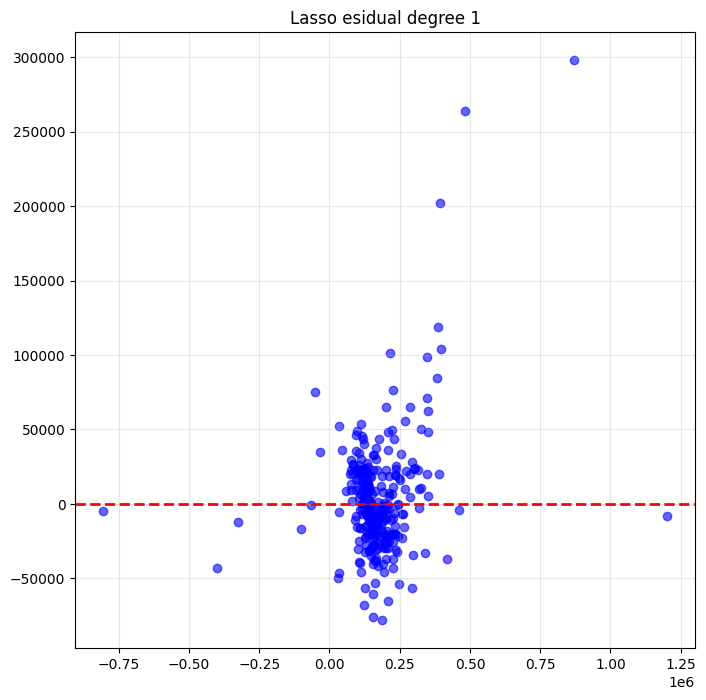

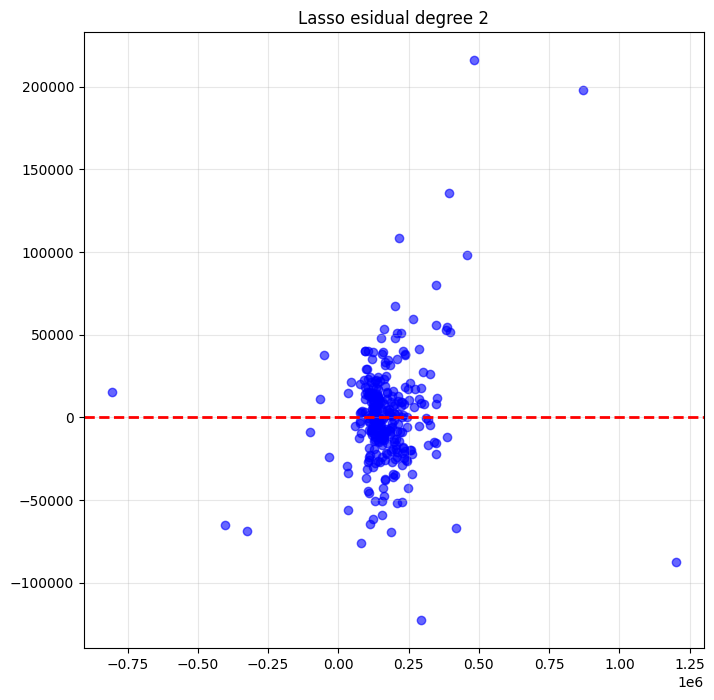

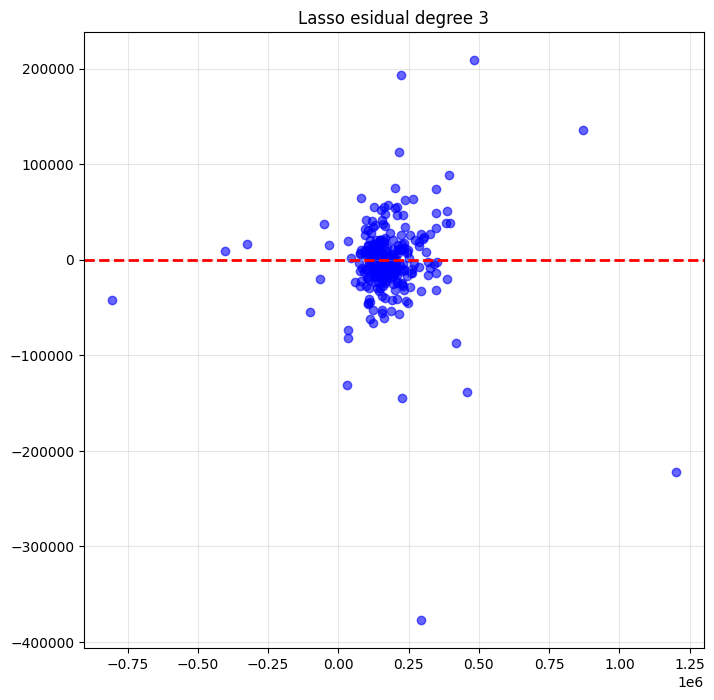

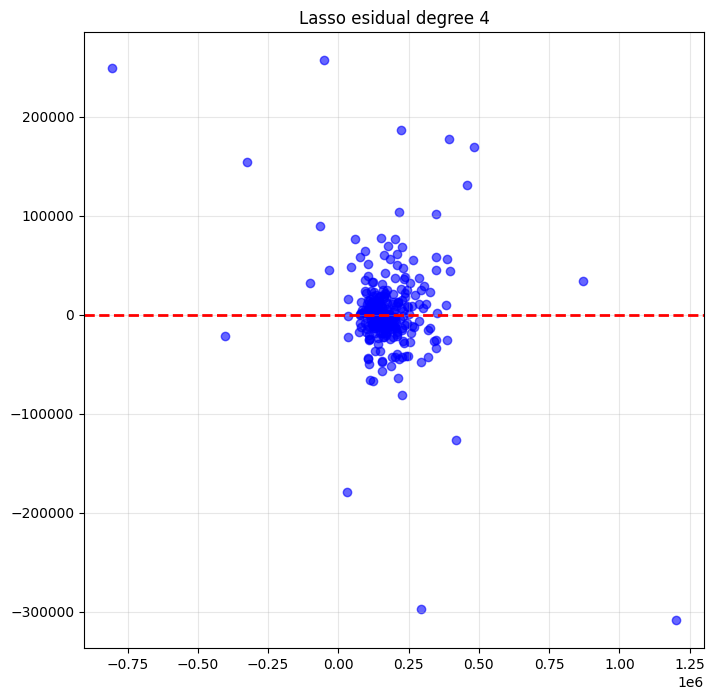

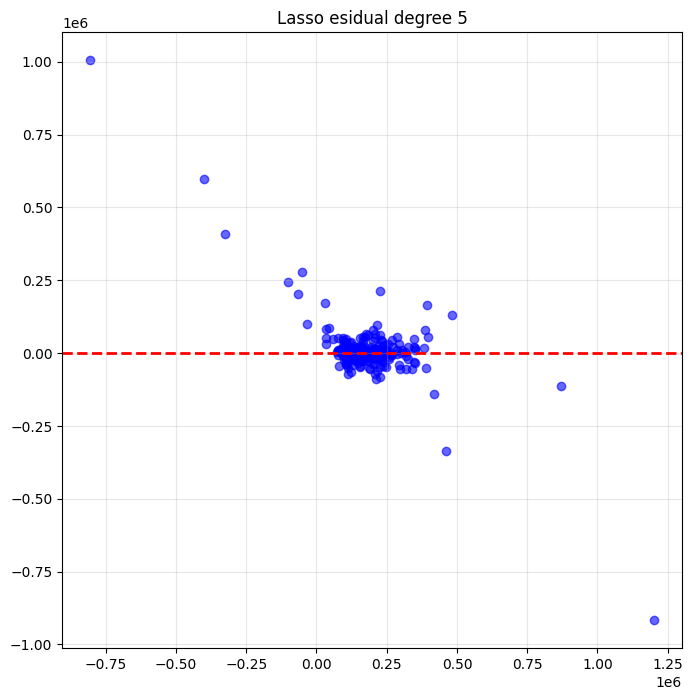

In [65]:
for degree in degrees :
    lasso_pred = models[degree]['lasso prediction']
    residual = lasso_residual_dict[degree]

    plt.figure(figsize=(8,8))
    plt.scatter(lassso_pred, residual, color='blue', alpha=0.6)
    plt.axhline(0, color='red', linestyle='--', linewidth=2)
    plt.title(f"Lasso esidual degree {degree}")
    plt.grid(alpha=0.3)
    plt.show()

# Visualization Ridge Polynomial

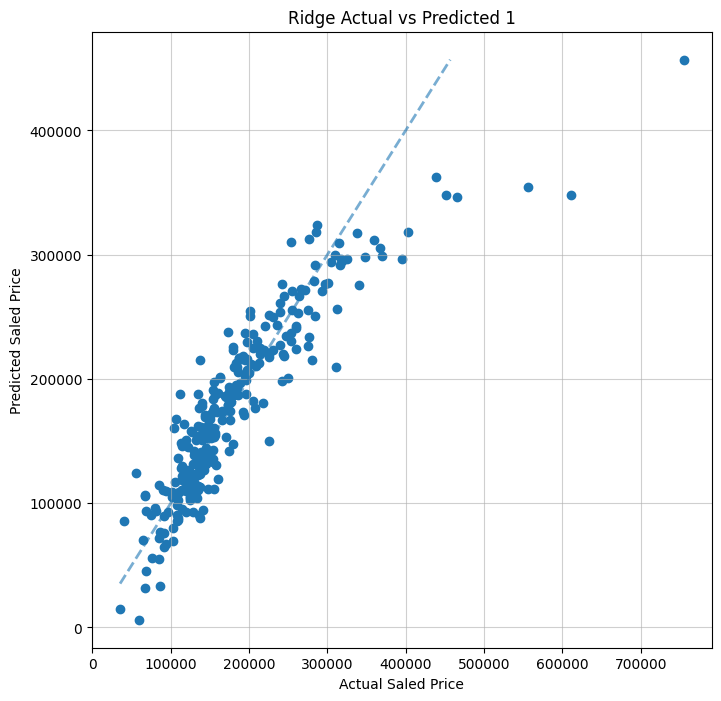

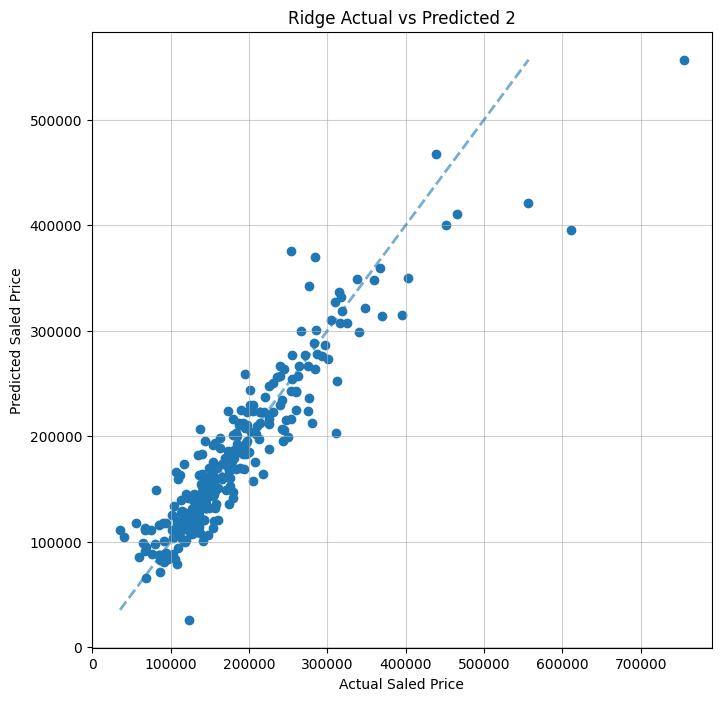

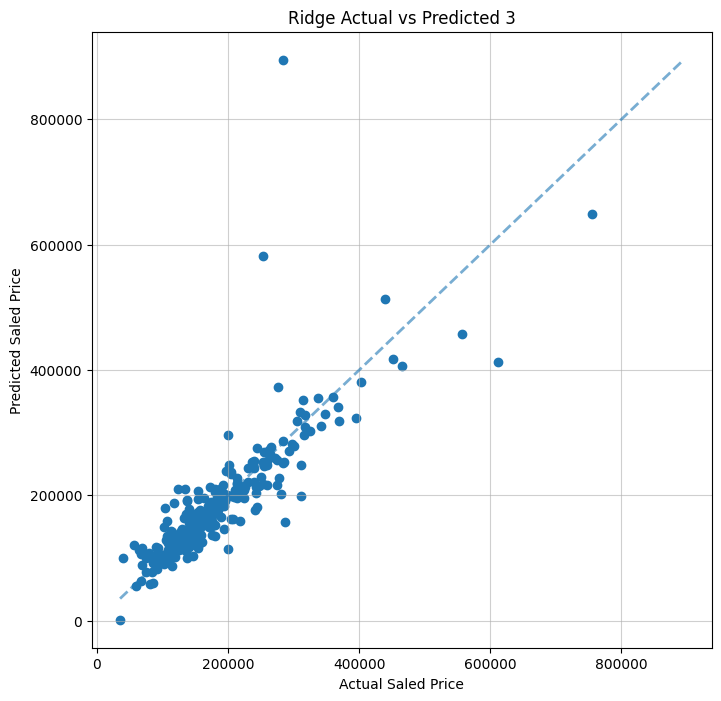

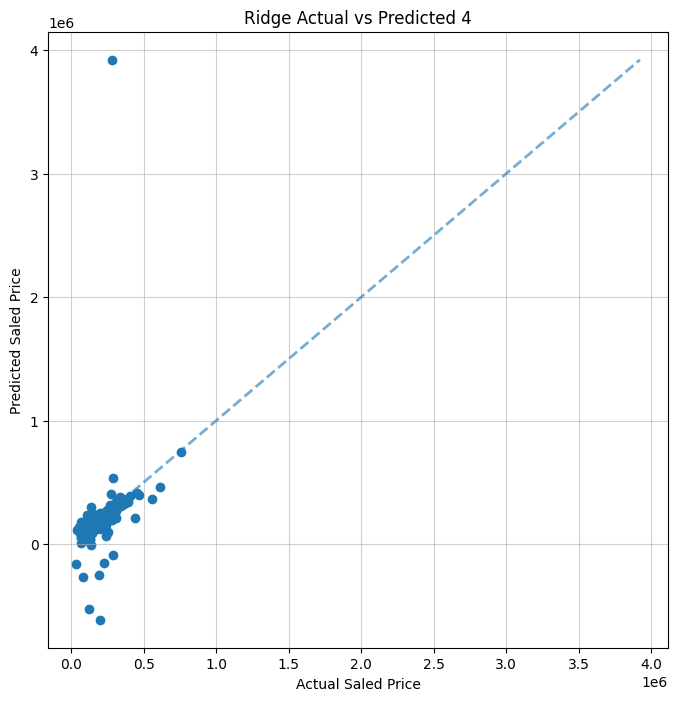

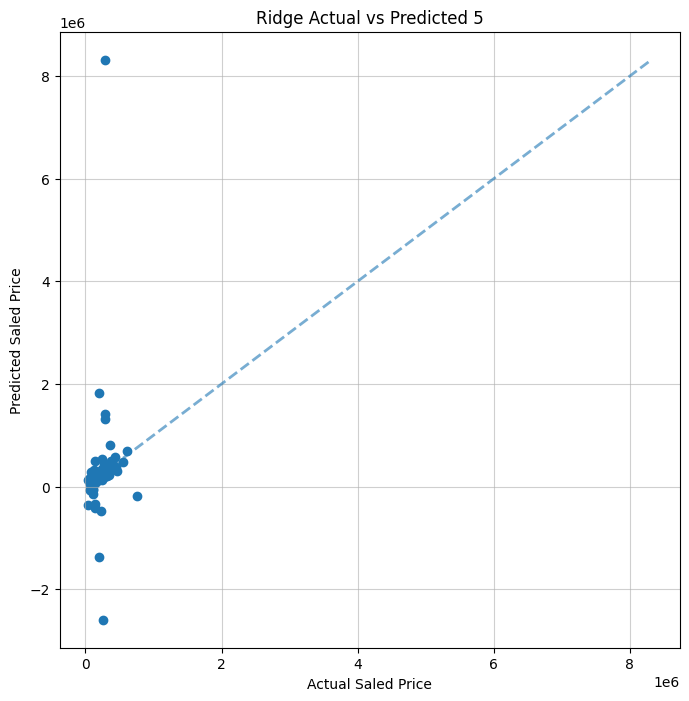

In [67]:
for degree in degrees :
    y_pred = models[degree]['ridge prediction']
    plt.figure(figsize=(8,8))
    plt.scatter(y_test, y_pred)
    plt.plot(
        [y_test.min(),y_pred.max()], 
        [y_test.min(),y_pred.max()],
        lw=2,
        ls='--',
        alpha=0.6
    )
    plt.grid(alpha=0.6)
    plt.xlabel("Actual Saled Price")
    plt.ylabel("Predicted Saled Price")
    plt.title(f"Ridge Actual vs Predicted {degree}")
    plt.show()

# Visualization Lasso Polynomial

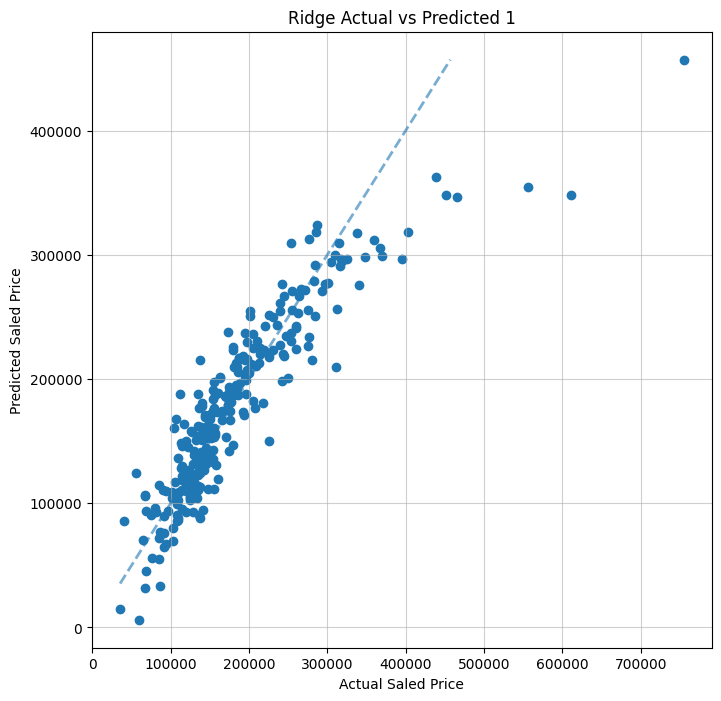

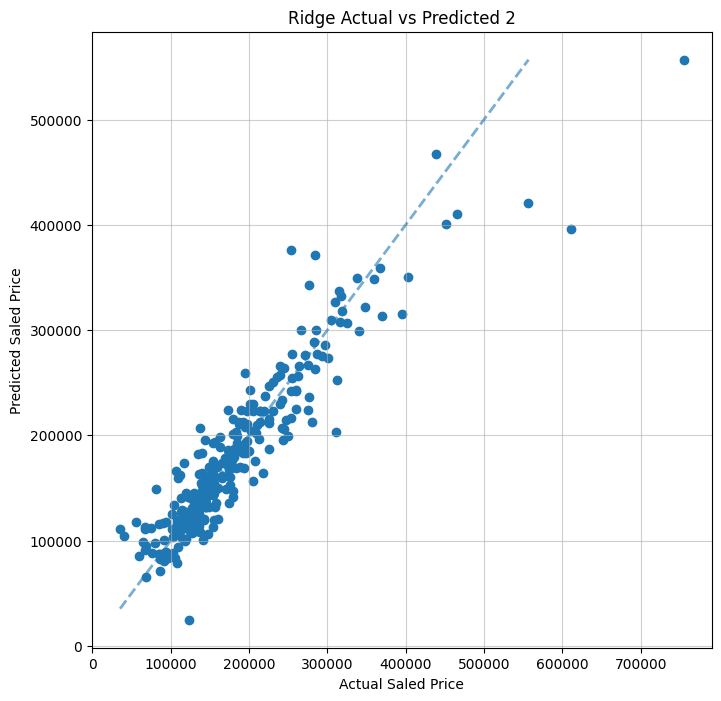

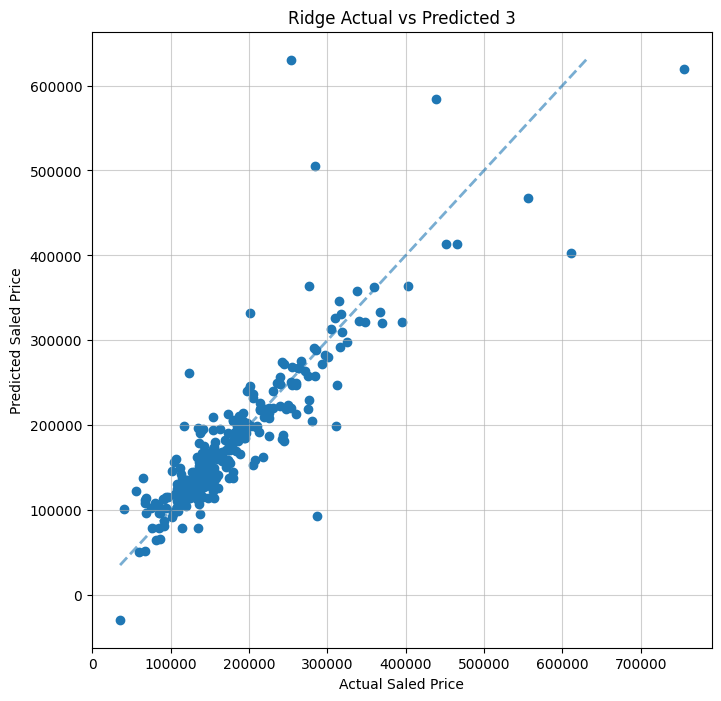

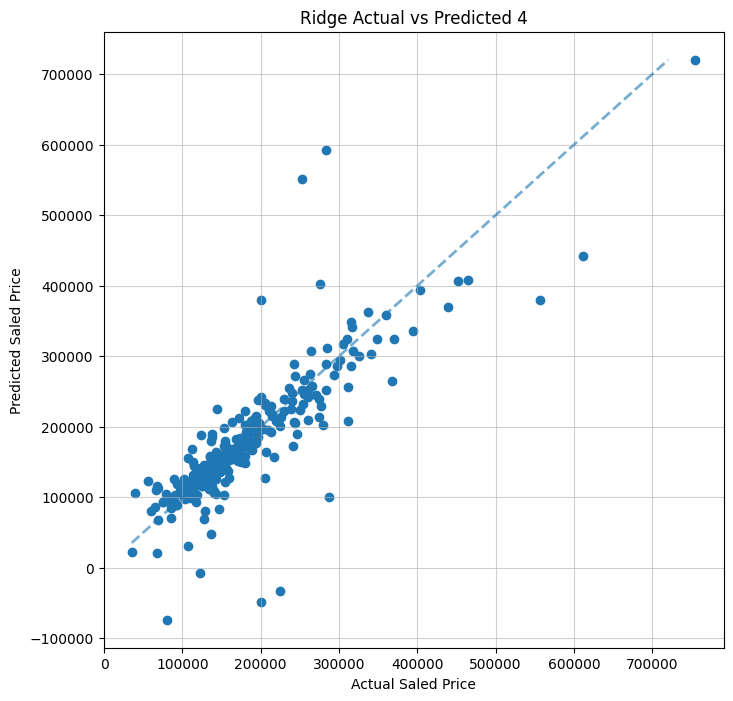

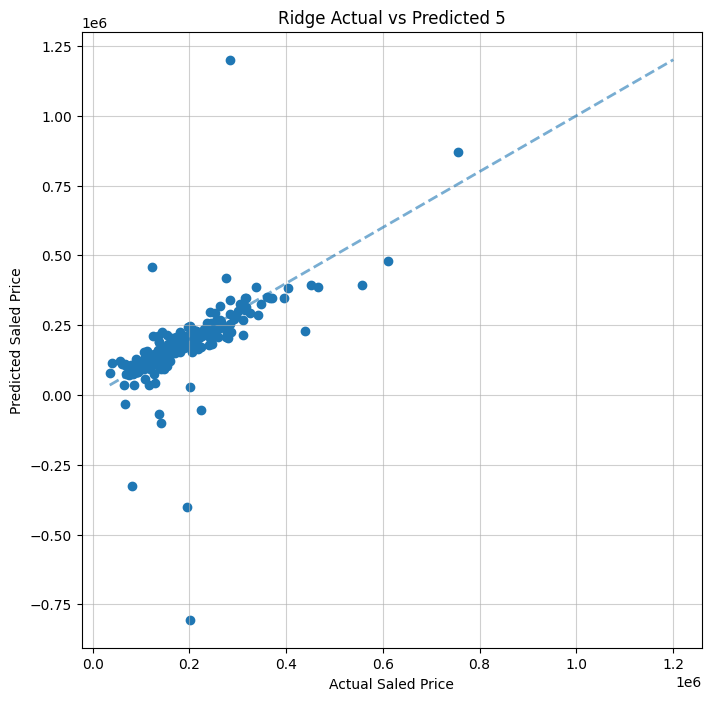

In [68]:
for degree in degrees :
    y_pred = models[degree]['lasso prediction']
    plt.figure(figsize=(8,8))
    plt.scatter(y_test, y_pred)
    plt.plot(
        [y_test.min(),y_pred.max()], 
        [y_test.min(),y_pred.max()],
        lw=2,
        ls='--',
        alpha=0.6
    )
    plt.grid(alpha=0.6)
    plt.xlabel("Actual Saled Price")
    plt.ylabel("Predicted Saled Price")
    plt.title(f"Ridge Actual vs Predicted {degree}")
    plt.show()

# Result
For second-degree polynomial regression, Ridge regression was selected as the best model over Lasso. Although Lasso yielded a mean residual slightly closer to zero, Ridge produced lower MAE and RMSE values, as well as a slightly higher R². Therefore, based on overall predictive performance, Ridge is superior.